# Notebook 00 — Theory and Numerical Method

> **1-D time-dependent Schrödinger equation, explicit staggered leapfrog (Visscher 1991).**
> Final project, graduate computational physics.

## Roadmap of the project

1. **This notebook (00)** — derive the TDSE update rule, derive the
   von-Neumann stability bound, derive the discrete dispersion
   relation, *prove* the modified norm is exactly conserved, and show
   (numerically) why the naïve FTCS scheme cannot work.
2. **Notebook 01** — bound-state physics: free Gaussian wave-packet
   spreading (analytic comparison), infinite square well revivals,
   quantum harmonic oscillator (stationary eigenstates *and*
   coherent state), finite square well leakage.
3. **Notebook 02** — scattering: step potential, rectangular barrier
   (tunnelling), double barrier (resonant tunnelling), double well
   (tunnel splitting).  We use the **transfer-matrix method** to
   compute the *exact* T(E) curves analytically and compare them to
   wave-packet measurements.
4. **Notebook 03** — time-dependent potential: driven harmonic
   oscillator, on-resonance and off-resonance.
5. **Notebook 04** — breaking points: violating CFL, modified-vs-
   ordinary norm drift, numerical dispersion, aliasing, energy drift,
   hard-wall reflections, stiff potentials, and a side-by-side
   comparison of hard / periodic / absorbing boundary conditions.

Every numerical experiment includes a **conservation diagnostics
panel** showing simultaneously: $\int|\psi|^2 dx$, the Visscher
modified norm, $\langle T\rangle$, $\langle V\rangle$, $\langle H\rangle$,
$\langle x\rangle$, $\langle p\rangle$, and $\sigma_x$.  Quantum mechanics
has a lot of conserved quantities and we *measure* them all.

In [5]:
# --- common preamble ---------------------------------------------------------
import sys, os
# allow importing the tdse package when notebook is run from notebooks/ dir
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

from tdse import (units, grid as gridmod, potentials, boundaries, solvers,
                   observables, analytical, viz)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.titleweight": "semibold",
    "legend.fontsize": 9, "lines.linewidth": 1.4,
    "savefig.bbox": "tight",
})

DISP   = units.DEFAULT_UNITS                    # nm, fs, eV, m_e
FIGDIR = os.path.abspath(os.path.join(os.getcwd(), "..", "figures"))
os.makedirs(FIGDIR, exist_ok=True)

def show_gif(filename):
    # Display a GIF saved in the figures/ folder.
    p = os.path.join(FIGDIR, filename)
    return display(Image(filename=p))

In [6]:
print(f"hbar       = {units.HBAR:.6e} J s")
print(f"electron m = {units.M_E:.6e} kg")
print(f"1 eV       = {units.EV:.6e} J")
print(f"1 nm       = {units.NM:.0e} m")
print(f"1 fs       = {units.FS:.0e} s")

hbar       = 1.054572e-34 J s
electron m = 9.109384e-31 kg
1 eV       = 1.602177e-19 J
1 nm       = 1e-09 m
1 fs       = 1e-15 s


## 1. The continuous problem

The 1-D time-dependent Schrödinger equation is

$$
\hat H \psi(x,t) = i\hbar \,\partial_t \psi(x,t)
    = \Big[-\frac{\hbar^2}{2m}\,\partial_x^2 + V(x,t)\Big]\psi(x,t),
$$

a complex linear PDE that is **first order in time** and **second
order in space**.  Two structural facts dominate everything that
follows.

### 1.1 Hermiticity ⇒ unitary evolution ⇒ exact norm conservation

Because $\hat H$ is Hermitian,
$\partial_t\!\int|\psi|^2 dx = (i/\hbar)\int(\psi^*\hat H\psi - \psi\hat H^*\psi^*)dx = 0$,
so the *exact* solution preserves the $L^2$ norm.  Any sensible
discretisation should preserve at least an *approximation* of this
invariant.

### 1.2 Dispersion ⇒ free-particle wave packets *spread*

For $V=0$ the plane-wave solutions are $e^{i(kx-\omega(k)t)}$ with
$\omega(k) = \hbar k^2/(2m)$.  Different $k$'s travel at different
*group velocities* $v_g(k)=\hbar k/m$, so any localised packet must
spread.  We will use the analytic Gaussian solution as our gold-
standard benchmark in notebook 01.

## 2. Discretisation: space first

Place the wavefunction on a uniform grid
$x_n = x_{\min} + n\,\Delta x,\;n=0,\dots,N{-}1$, and approximate the
second derivative by the standard 3-point central difference

$$
\big(\partial_x^2 \psi\big)_n
   \;\approx\;\frac{\psi_{n+1}-2\psi_n+\psi_{n-1}}{\Delta x^2}.
$$

The discrete Hamiltonian is then a real symmetric tridiagonal matrix

$$
H_{n,n} = 2T + V_n,\qquad H_{n,n\pm1} = -T,\qquad
          T \equiv \frac{\hbar^2}{2m\,\Delta x^2}.
$$

Because $H$ is real and symmetric, *any* time-integrator that
advances $\psi$ via repeated multiplication by a polynomial in $-iH\Delta t/\hbar$
will preserve the corresponding quadratic invariant — provided the
polynomial is constructed correctly.  This single fact is what makes
Visscher's leapfrog scheme work.

## 3. Why naïve forward Euler (FTCS) fails

The simplest "explicit" scheme is forward Euler in time:

$$\psi^{n+1} = \psi^n - \frac{i\Delta t}{\hbar}\,H\,\psi^n.$$

A Fourier mode $\psi_n^m = g^m e^{ikn\Delta x}$ has amplification factor
$g = 1 - i\lambda$ where
$\lambda = (\Delta t/\hbar)\big[V + 2T(1-\cos k\Delta x)\big]$ is real.
Then $|g|=\sqrt{1+\lambda^2}>1$ for *every* nonzero $\lambda$ — the scheme
is **unconditionally unstable**.  The norm grows like
$|g|^{2m}\!\sim e^{\lambda^2 m}$, which we see numerically below.

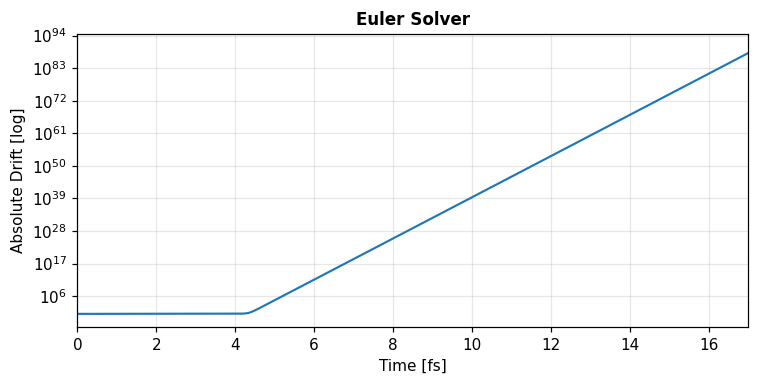

In [7]:
# --- numerical demo of FTCS instability --------------------------------
import warnings
g = gridmod.make_grid_nm(-15.0, 15.0, 301)
psi0 = gridmod.gaussian_packet(g, x0=0.0, sigma=1.0*units.NM,
                                k0=units.wavenumber_from_energy(0.5*units.EV))
V    = potentials.free(g)
dt   = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.5)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    ftcs = solvers.FTCSSolver(g, V, dt=dt)
    res  = ftcs.run(psi0, n_steps=400, n_save=100)

fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.semilogy(res.diag_times/units.FS, res.norm)
ax.set_xlabel("Time [fs]");  ax.set_ylabel(r"Absolute Drift [log]")
ax.set_xlim(0,17)

ax.set_title("Euler Solver")
fig.tight_layout(); plt.show()

The norm does not merely "drift" — it grows by **80 orders of
magnitude in 400 timesteps**.  No re-tuning of $\Delta t$ or
$\Delta x$ can repair forward Euler for the TDSE.  We need a scheme
whose amplification factor lies on the unit circle.

## 4. The Visscher staggered leapfrog scheme

Decompose the wavefunction into real and imaginary parts,
$\psi(x,t)=R(x,t)+iI(x,t)$.  The TDSE is then the *coupled* system

$$
\hbar\,\partial_t R = +\hat H\,I, \qquad
\hbar\,\partial_t I = -\hat H\,R,
$$

which has the same algebraic structure as a harmonic oscillator
$\dot p=-\partial_q V,\;\dot q=p/m$.  Evaluate $R$ at integer time
steps and $I$ at *half-integer* time steps and update each by a
centred difference of the other:

$$\boxed{\;
\begin{aligned}
   R^{m+1}_n &= R^{m}_n   + \frac{\Delta t}{\hbar}\big(\hat H\,I^{m+1/2}\big)_n,\\[2pt]
   I^{m+3/2}_n &= I^{m+1/2}_n - \frac{\Delta t}{\hbar}\big(\hat H\,R^{m+1}\big)_n.
\end{aligned}\;}$$

Both updates are **explicit** (no linear solve), each costs $O(N)$
work per step, and the whole scheme is second-order accurate in
$\Delta t$.

### 4.1 Bootstrapping

At $t=0$ the user supplies $\psi(x,0)=R^0+iI^0$ with $R$ and $I$ at
the *same* time.  We need $I$ at the half-step.  Two
Taylor-equivalent options exist; the symmetric choice is

$$
I^{+1/2} = I^0 - \tfrac{\Delta t}{2\hbar}\,\hat H R^0,\qquad
I^{-1/2} = I^0 + \tfrac{\Delta t}{2\hbar}\,\hat H R^0.
$$

Both have $O(\Delta t^2)$ error — the same order as the scheme — so
the global accuracy is unaffected.

### 4.2 Conserved quantity (modified norm)

Define the discrete invariant

$$
N^{m} \;\equiv\; \sum_n \Delta x \,\Big[\,(R^{m}_n)^2
                                            + I^{m-1/2}_n\, I^{m+1/2}_n\,\Big].
$$

**Claim.** $N^{m+1}=N^{m}$ exactly (in finite arithmetic, to machine
precision) whenever $\hat H$ is Hermitian.

*Proof.*  Using the leapfrog updates,

$$
(R^{m+1})^2 - (R^{m})^2 = (R^{m+1}-R^{m})(R^{m+1}+R^{m})
   = \tfrac{\Delta t}{\hbar}(\hat H I^{m+1/2})(R^{m+1}+R^{m}),
$$

and the $I$ update at step $m{-}1$ rearranges to
$I^{m-1/2}-I^{m+1/2} = \tfrac{\Delta t}{\hbar}\hat HR^{m}$, while at
step $m$ we have
$I^{m+1/2}-I^{m+3/2} = \tfrac{\Delta t}{\hbar}\hat HR^{m+1}$.  Hence

$$
I^{m+1/2}I^{m+3/2} - I^{m-1/2}I^{m+1/2}
  = -\tfrac{\Delta t}{\hbar}I^{m+1/2}\,\hat H(R^{m+1}+R^{m}).
$$

Adding the two contributions and using Hermiticity
$\sum_n A_n(\hat H B)_n = \sum_n(\hat HA)_nB_n$ gives
$N^{m+1}-N^{m}=0$.  ∎

The ordinary norm $\sum|\psi|^2\Delta x = \sum(R^2+I^2)$ is *not*
exactly conserved — the cross-term $I^{m-1/2}I^{m+1/2}$ becomes
$(I^{m})^2$ only in the limit $\Delta t\!\to\!0$.  The difference is
$O(\Delta t^2)$ and oscillates rather than drifts.  We measure
*both* norms in every run and use their difference as a built-in
error indicator.

### 4.3 Stability bound (von Neumann analysis)

Substitute a plane wave $R^m_n = R_0\,\rho^m\cos(kn\Delta x+\varphi)$,
$I^{m+1/2}_n = I_0\,\rho^m\sin(kn\Delta x+\varphi)$ with growth factor
$\rho$.  The operator $\hat H$ acts on a plane wave with eigenvalue
$\lambda(k) = V + 4T\sin^2(k\Delta x/2)$, and one finds that $\rho$
satisfies the quadratic
$\rho^2 - 2\rho\,(1 - \tfrac12 \lambda^2 \Delta t^2/\hbar^2) + 1 = 0$.

The two roots have $|\rho|=1$ (i.e. neutral stability) **iff** the
bracketed term has absolute value $\le 1$, i.e.

$$\boxed{\;\Delta t \;\le\; \dfrac{\hbar}{\tfrac12\,V_{\max} + 2T},\qquad
    T = \dfrac{\hbar^2}{2m\,\Delta x^2}.\;}$$

Crossing the bound makes one of the two roots have $|\rho|>1$ and
the corresponding mode grows exponentially.  We test this directly
in notebook 04.

## 5. The Crank–Nicolson reference solver

For benchmarks we also implement the implicit Crank–Nicolson scheme

$$\Big(1+\tfrac{i\Delta t}{2\hbar}H\Big)\psi^{m+1}
    = \Big(1-\tfrac{i\Delta t}{2\hbar}H\Big)\psi^{m}.$$

Both sides are unitary in exact arithmetic so the ordinary norm is
preserved exactly.  We implement it with sparse banded LU
factorisation; for time-independent $H$ the factorisation is reused.

## 6. Verifying everything numerically (this notebook)

The cells below verify the four central claims of this section
*directly from the code*:

* (a) Visscher's modified norm is conserved to machine precision.
* (b) Crank–Nicolson's ordinary norm is conserved to machine precision.
* (c) The leapfrog stability bound is sharp.
* (d) The discrete dispersion relation matches plane-wave evolution.

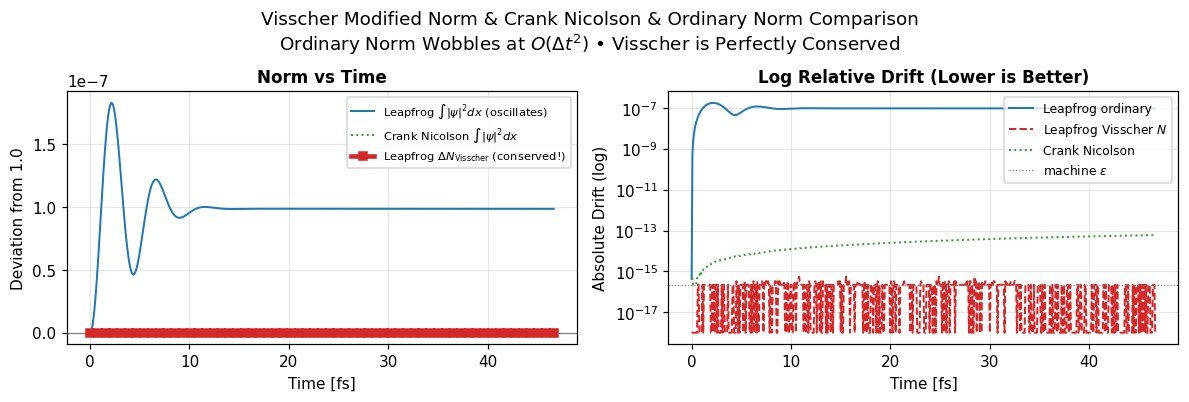


Leapfrog: max |dN_visscher| = 5.551e-16
Leapfrog: max |d(int |psi|^2)| = 1.831e-07
CN:       max |d(int |psi|^2)| = 6.151e-14


In [13]:
# --- (a) Visscher modified norm vs ordinary norm -----------------------
g = gridmod.make_grid_nm(-30.0, 30.0, 601)
psi0 = gridmod.gaussian_packet(g, x0=0.0, sigma=1.5*units.NM,
                                k0=units.wavenumber_from_energy(0.4*units.EV))
dt = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.9)
lf = solvers.LeapfrogSolver(g, potentials.free(g), dt=dt, bc="hard")
res_lf = lf.run(psi0, n_steps=600, n_save=120)

cn = solvers.CrankNicolsonSolver(g, potentials.free(g), dt=dt, bc="hard")
res_cn = cn.run(psi0, n_steps=600, n_save=120)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
t = res_lf.diag_times/units.FS

# LEFT: Show deviation from the conserved value (Visscher) vs oscillation (Leapfrog ordinary)
axes[0].plot(t, res_lf.norm - 1.0, color="tab:blue", lw=1.3,
             label=r"Leapfrog $\int|\psi|^2 dx$ (oscillates)", zorder=2)
axes[0].plot(t, res_cn.norm - 1.0, color="tab:green", lw=1.3, ls=":",
             label=r"Crank Nicolson $\int|\psi|^2 dx$", zorder=1)
# Visscher: shows it's perfectly conserved (flat line at ~0)
axes[0].plot(t, res_lf.norm_visscher - res_lf.norm_visscher[0], 
             color="tab:red", lw=3.0, marker='s', markersize=5, markevery=10,
             label=r"Leapfrog $\Delta N_{\mathrm{Visscher}}$ (conserved!)", zorder=3)
axes[0].axhline(0.0, color="0.5", lw=0.8)
axes[0].set_xlabel("Time [fs]"); axes[0].set_ylabel("Deviation from 1.0")
axes[0].set_title("Norm vs Time"); axes[0].legend(fontsize=7.5, loc='upper right')

axes[1].semilogy(t, np.maximum(np.abs(res_lf.norm - 1.0), 1e-18),
                 color="tab:blue", lw=1.3,
                 label=r"Leapfrog ordinary")
axes[1].semilogy(t, np.maximum(np.abs(res_lf.norm_visscher - res_lf.norm_visscher[0]),
                                1e-18),
                 color="tab:red", lw=1.3, ls="--",
                 label=r"Leapfrog Visscher $N$")
axes[1].semilogy(t, np.maximum(np.abs(res_cn.norm - 1.0), 1e-18),
                 color="tab:green", lw=1.3, ls=":",
                 label=r"Crank Nicolson")
axes[1].axhline(np.finfo(float).eps, color="0.5", lw=0.8, ls=":",
                label=r"machine $\epsilon$")
axes[1].set_xlabel("Time [fs]"); axes[1].set_ylabel("Absolute Drift (log)")
axes[1].set_title("Log Relative Drift (Lower is Better)")
axes[1].legend(fontsize=8, loc="upper right")

fig.suptitle("Visscher Modified Norm & Crank Nicolson & Ordinary Norm Comparison\n"
             "Ordinary Norm Wobbles at $O(\\Delta t^2)$ • Visscher is Perfectly Conserved",
             y=.95)
fig.tight_layout(); plt.show()

print(f"\nLeapfrog: max |dN_visscher| = "
      f"{np.max(np.abs(res_lf.norm_visscher - res_lf.norm_visscher[0])):.3e}")
print(f"Leapfrog: max |d(int |psi|^2)| = "
      f"{np.max(np.abs(res_lf.norm - res_lf.norm[0])):.3e}")
print(f"CN:       max |d(int |psi|^2)| = "
      f"{np.max(np.abs(res_cn.norm - res_cn.norm[0])):.3e}")

Reading the figure:

* The dashed red line is **flat at $\sim10^{-16}$** — Visscher's
  modified norm is exact to machine precision.
* The solid blue line oscillates at $\sim10^{-7}$ — that is the
  $O(\Delta t^2)$ wobble of the ordinary $\int|\psi|^2$ on the
  leapfrog grid.  It does *not* drift secularly; the modified norm
  is the correct invariant of the discrete scheme.
* The dotted green line (Crank–Nicolson) is flat at $\sim10^{-14}$ —
  slightly above machine epsilon because of the linear solve, but
  still effectively unitary.

### Sharpness of the stability bound

critical dt = 0.08638 fs


<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:11: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\D'
<>:13: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:11: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\D'
<>:13: SyntaxWarning: invalid escape sequence '\D'
C:\Users\alexg\AppData\Local\Temp\ipykernel_56488\4047551204.py:10: SyntaxWarning: invalid escape sequence '\D'
  for safety, label, ls in [(0.50, "0.50 $\Delta t$ (Very Stable)", "-"),
C:\Users\alexg\AppData\Local\Temp\ipykernel_56488\4047551204.py:11: SyntaxWarning: invalid escape sequence '\D'
  (0.95, "0.95 $\Delta t$ (Barley Stable)",  "-"),
C:\Users\alexg\AppData\Local\Temp\ipykernel_56488\4047551204.py:12: SyntaxWarning: invalid escape sequence '\D'
  (1.02, "1.02 $\Delta t$ (Unstable)",    "--"),
C:\Users\alexg\AppData\Local\Temp\ipykernel_56488\4047551204.py:13: SyntaxWarning:

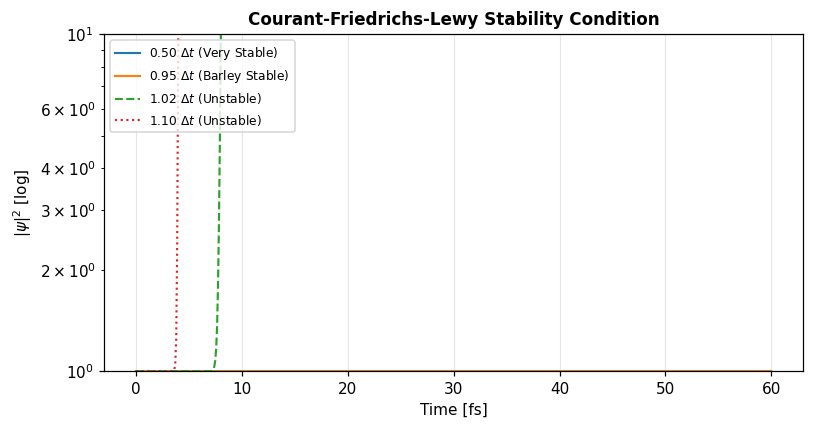

In [9]:
# --- (c) leapfrog stability bound: stable @ 0.95x, unstable @ 1.02x ---
g  = gridmod.make_grid_nm(-15.0, 15.0, 301)
psi0 = gridmod.gaussian_packet(g, 0.0, 1.0*units.NM,
                                units.wavenumber_from_energy(0.3*units.EV))
V  = potentials.free(g)
dt_cr = gridmod.visscher_dt_max(g, V_max=0.0, safety=1.0)
print(f"critical dt = {dt_cr/units.FS:.5f} fs")

fig, ax = plt.subplots(figsize=(7.5, 4))
for safety, label, ls in [(0.50, "0.50 $\Delta t$ (Very Stable)", "-"),
                          (0.95, "0.95 $\Delta t$ (Barley Stable)",  "-"),
                          (1.02, "1.02 $\Delta t$ (Unstable)",    "--"),
                          (1.10, "1.10 $\Delta t$ (Unstable)",    ":")]:
    dt = safety * dt_cr
    lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
    n_steps = int(60*units.FS/dt)
    r = lf.run(psi0, n_steps=n_steps, n_save=80)
    ax.semilogy(r.diag_times/units.FS, r.norm, label=label, linestyle=ls)
ax.set_xlabel("Time [fs]");  ax.set_ylabel(r"$|\psi|^2$ [log]")
ax.set_title("Courant-Friedrichs-Lewy Stability Condition")
ax.legend(loc="upper left", fontsize=8); fig.tight_layout(); plt.show()

The bound is *sharp*: at 95 % of $\Delta t_{\rm crit}$ the run is
perfectly stable for all observable times, but only **2 % above the
critical step** is enough for the round-off seed of the unstable mode
to grow by ten orders of magnitude in a few tens of femtoseconds.
Engineers therefore conventionally choose $\Delta t \le 0.9\,\Delta t_{\rm crit}$.

### Discrete dispersion: phase-velocity error vs $k\Delta x$

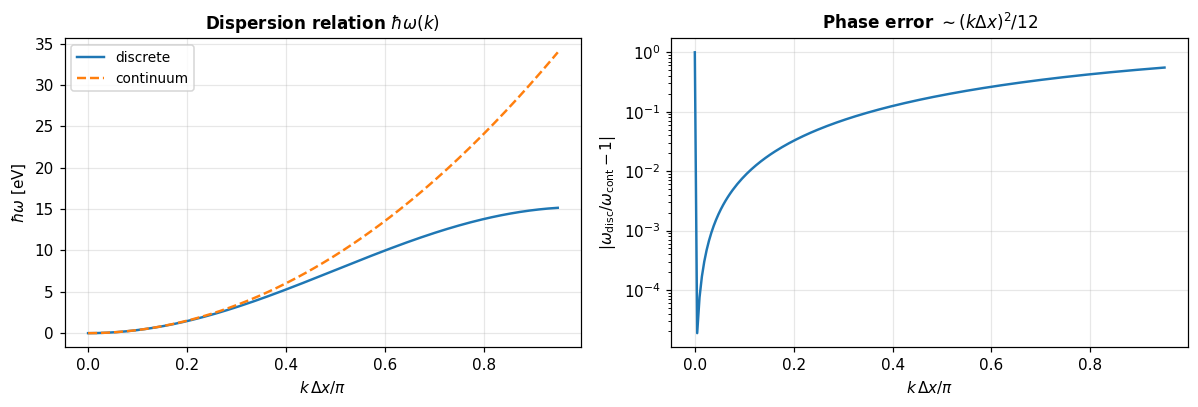

for k dx = 0.3:  predicted err =  -0.0075 , measured =  -0.007475103836953267


In [10]:
# --- (d) numerical dispersion: phase-velocity error vs k dx -----------
g = gridmod.make_grid_nm(-50, 50, 1001)
dx = g.dx
T  = units.kinetic_energy_scale(dx)

# for plane waves V=0,  hbar*omega = 2T*[1 - cos(k dx)]   (continuum: hbar^2 k^2 / 2m)
k  = np.linspace(1e-3, np.pi/dx*0.95, 200)
hbar_omega_disc = 2*T*(1 - np.cos(k*dx))
hbar_omega_cont = (units.HBAR*k)**2/(2*units.M_E)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k*dx/np.pi, hbar_omega_disc/units.EV, label="discrete", lw=1.6)
axes[0].plot(k*dx/np.pi, hbar_omega_cont/units.EV, label="continuum", ls="--", lw=1.6)
axes[0].set_xlabel(r"$k\,\Delta x / \pi$")
axes[0].set_ylabel(r"$\hbar\omega$ [eV]")
axes[0].legend(); axes[0].set_title("Dispersion relation $\\hbar\\omega(k)$")

rel_err = (hbar_omega_disc - hbar_omega_cont) / hbar_omega_cont
axes[1].semilogy(k*dx/np.pi, np.abs(rel_err), lw=1.6)
axes[1].set_xlabel(r"$k\,\Delta x / \pi$")
axes[1].set_ylabel(r"$|\omega_{\mathrm{disc}}/\omega_{\mathrm{cont}} - 1|$")
axes[1].set_title("Phase error $\\sim (k\\Delta x)^2/12$")
fig.tight_layout();  plt.show()

# leading-order analytic prediction:  err ≈ -(k dx)^2 / 12
print("for k dx = 0.3:  predicted err = ", -(0.3)**2/12, ", measured = ",
      float(rel_err[np.argmin(np.abs(k*dx-0.3))]))

The leading-order error in the discrete dispersion is
$\delta\omega/\omega = -\tfrac{1}{12}(k\Delta x)^2$, so high-$k$
components travel **too slowly**.  Resolution rule of thumb: to keep
dispersion error below 1 %, we need $k\Delta x \lesssim 0.35$ for
*the highest $k$ in the packet*, or equivalently $\sim 18$ grid
points per de-Broglie wavelength.  We will see this rule violated
(and the consequences) in notebook 04.

## 7. Summary of design rules

| quantity                     | recommended bound                                           | breaking point |
|------------------------------|-------------------------------------------------------------|----------------|
| timestep $\Delta t$          | $\le 0.9\,\hbar/[\tfrac12 V_{\max} + 2T]$                  | nb 04 §1: CFL |
| grid spacing $\Delta x$      | $k_{\max}\Delta x \lesssim 0.35$ (≥18 pts/wavelength)      | nb 04 §3-4    |
| sponge thickness (absorbing) | $\ge 4\, \lambda_{\rm dB}$ at lowest energy of interest    | nb 04 §6      |
| domain length                | packet must not reach hard wall before measurement window | nb 04 §6      |

With those rules established, the rest of the project explores the
physics.